## **DS 5030 Understanding Uncertainty Lab 6 - Demand Experimentation and Revenue Management**

### **By Fiona St. Clair, Sayuri Nagai, Maddie Smith, and Kaitlyn McFadden**

<div style="border: 2px solid blue; padding: 8px 12px;">
cells in blue are notes

<div style="border: 2px solid red; padding: 8px 12px;">
cells in red are questions marked to answer

***

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100) # Sets a random seed for reproducibility

# answers if a customer sees this price, what's the chance they buy?
def purchase_probability(price): 
    price = np.asarray(price, dtype=float) 
    return (
        # Each line is one customer segment with its own price tolerance
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

# runs a simulation of sales for a given price and mean number of customers
def sales(price=14.0, rng=None, mean_customers=30):
    # Validate inputs 
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    # Use the provided random number generator or create a new one
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

<div style="border: 2px solid blue; padding: 8px 12px;">
big picture idea: we're trying to find the best price and every price we try is its own experiment, which costs money. we want to find the optimal price with the least number of experiments 

## Sequential Experimentation

- In the real world, we have to make decisions in real time
- Data arrive as we're taking action, and we have to update our behavior
- We're going to look at a simple $Z$-test, and investigate some options for search

<div style="border: 2px solid blue; padding: 8px 12px;">

- sequential meaning we try a price, see what happens, adjust, and try again
- we use a z-test (tests whether 2 averages differ) as the decision tool at each step

## Revenue
- The **revenue** at a price $p$ is
$$
R(p) = \text{sales}(p) \times p
$$
- Sellers typically want to maximize revenue (or profit): Raising $p$ slightly increases the price paid for each unit sold, but reduces the number of units sold. A revenue-maximizing price must satisfy:
$$
R'(p^*) = \underbrace{\text{sales}(p^*) \times 1}_{\text{Increased revenue per sale}}+ \underbrace{\left.\dfrac{d \text{sales}(p)}{dp}\right|_{p=p^*}}_{\text{Lost marginal sales}} \times p^* = 0
$$
- This helps us think about trade-offs, but this is an idealized thought experiment: The world doesn't actually give us a `sales` function

## Revenue Management
- In the real world, we don't observe the $\text{sales}(p)$ function directly (you might model it, and we'll do that eventually, but a company like Uber often relies on experiments to adjust prices)
- Instead, you simply see how customers respond to changes in your pricing
- But changes in revenue are hard to attribute to a negative causal impact on sales, versus simply fewer customers engaging that day
- The lab is built around observing behavior, testing a hypothesis, and then updating prices
- This is called **stochastic optimization**: Each price you set is an experiment that yields information

<div style="border: 2px solid blue; padding: 8px 12px;">

- since the real world doesn't give us a sales functin, we can only see what customers do after we set a price
- but attribution here is difficult...so this experiment's design simplifies that
    - number of customers is random and doesn't depend on price
    - whether a custmer buys does depend on price
- Stochastic optimization meaning optimizing when the outcomes are random

## Key Function: `sales`
- The `sales(price=14.0, rng=None, mean_customers=30)` function is the core of the lab
- `mean_customers` scales the size of the market up and down: You'll want to be able to easily control the number of customers you experiment with later
- The rng argument is the numpy random number generator to use
- You set a `price`, and it returns a vector of customer choices (0=didn't buy, 1=buy) with a mean of your requested experiment size, `mean_customers`

<div style="border: 2px solid blue; padding: 8px 12px;">

You give it a price. It simulates one batch of customers walking in, each deciding to buy or not. It returns an array with one entry per customer: 1 = bought, 0 = didn't buy.

Three inputs
* price we're teesting
* rng/seed
* mean_customers, average number of customers who show up (default is 30)
    * this is the 'size' of the experiment

***
## 1. Comparing Two Prices
- Our `sales(price, rng)` function generates a number of customers and their sales choices
- The number of customers who "browse" isn't affect by the price you choose, but whether they purchase is effected: Higher prices lead to lower sales
- Because sales are random/stochastic, it's difficult to know whether a change in price is truly profitable or not

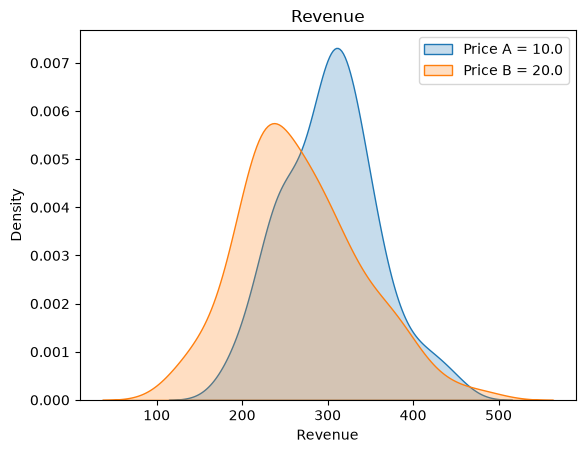

In [2]:
# Simulates running a store at two different prices for 100 days each, then plots how daily revenue is distributed at each price. 
# The goal is to show how noisy revenue is, which makes it hard to tell which price is better.

R = 100 # Test each price for 100 days
p_A = 10.0 # price A = $10
p_B = 20.0 # price B = $20
revenue_A = [ sales(p_A, rng=rng).sum() * p_A for t in range(R) ] # calculate revenue for price A over R days
revenue_B = [ sales(p_B, rng=rng).sum() * p_B for t in range(R) ] # calculate revenue for price B over R days
sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density") 
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
plt.legend()

<div style="border: 2px solid blue; padding: 8px 12px;">
At $10, almost everyone buys, so revenue is about 30 customers × ~$10 ≈ $300 a day.

At $20, only about 45% buy (the mid-range and premium segments), so revenue is about 30 × 0.45 × $20 ≈ $270 a day.

The two curves overlap a lot, so on any given day we can't tell which price is better. One bad day at $10 could look worse than a good day at $20.

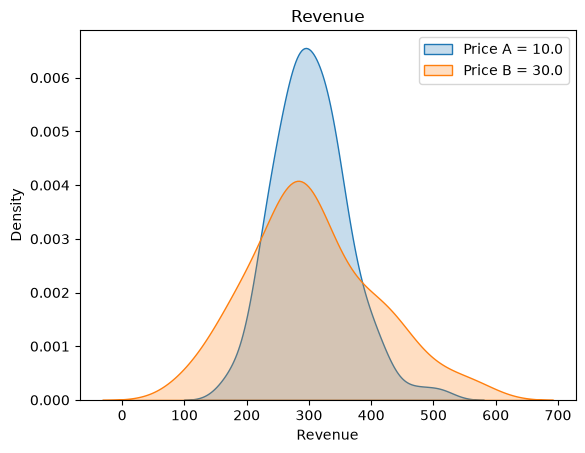

In [3]:
# same simulation but with higher price for B; shows how revenue distributions can overlap even when one price is clearly better than the other

R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 30.0
revenue_A = [ sales(p_A, rng=rng).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng).sum() * p_B for t in range(R) ]
sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
plt.legend()

## Two-Sample $Z$-Test
- How can we compare revenue at two different price points?
- In the diabetes management lab, we used a fully non-parametric approach to comparing metformin versus rostiglatzione versus lifestyle
- Now that we know more about how Bootstrapping and classical inference interact, we can convert that two-way comparison into a statistical test
- The key fact to know is that if $X$ and $Y$ are independent and normally distributed with means $\mu_X$ and $\mu_Y$ and standard deviations $\sigma_X$ and $\sigma_Y$, then $X-Y$ is normally distributed with mean $\mu_X - \mu_Y$ and standard deviation $\sqrt{\sigma_X^2 + \sigma_Y^2}$

<div style="border: 2px solid blue; padding: 8px 12px;">

Asking, is the difference I see between price A and price B real, or could it just be random noise?
- Null hypothesis (H0): the two prices have the same true average revenue per customer. Any difference you see is luck.
- Alternative: the true averages differ.

For the lab...price search is a trade off
- Near the optimum, nearby prices earn almost the same revenue, so the true difference is close to zero. 
- Every extra customer we test costs us, because some of them see a worse price.

## Two-Sample $Z$-Test
- For large samples, the CLT lets us apply the difference-of-normals reasoning to approximately Normal sample means
- So let $\bar{X}_{n_X}$ be the mean of a sample of IID random variables of size $n_X$ with means $\mu_X$ and standard deviations $\sigma_X$ (and similarly for $\bar{Y}_{n_Y}$)
- The expectation of $\bar{X}_{n_X}$ is $\mu_X$, and the standard deviation of $\bar{X}_{n_X}$ is $\sigma_X/\sqrt{n_X}$ (and similarly for $\bar{Y}_{n_Y}$)
- Then the difference in $\Delta = \bar{X}_{n_X}-\bar{Y}_{n_Y}$ is approximately Normally distributed, with mean $\mu_X - \mu_Y$ and standard deviation $\sqrt{\sigma_X^2/n_X + \sigma_Y^2/n_Y}$

<div style="border: 2px solid red; padding: 8px 12px;">

- What happens to the standard error of the mean as $n_X$ or $n_Y$ increase?
    * It shrinks, in proportion to 1/sqrt(n). To halve the SE, you need four times the customers.

- If $\mu_X - \mu_Y$ is close to zero, is a difference in means easier or more difficult to detect?
    * Harder. A small real effect is buried in noise, so you need a much larger sample to separate it.

</div>

## CIs for the Two-Sample $Z$-Test
- So the idea is: If $\bar{X}_{n_X}-\bar{Y}_{n_Y}$ has an approximately Normal sampling distribution with mean $\mu_X - \mu_Y$ and approximate the standard error with $\sqrt{\sigma_X^2/n_X + \sigma_Y^2/n_Y}$, we can compute, for instance, a 90% CI against a null of zero with
$$
\left( (\bar{X}_{n_X}-\bar{Y}_{n_Y}) - 1.645 \times \sqrt{\frac{s_X^2}{n_X} + \frac{s_Y^2}{n_Y}}, \quad (\bar{X}_{n_X}-\bar{Y}_{n_Y}) + 1.645 \times \sqrt{\frac{s_X^2}{n_X} + \frac{s_Y^2}{n_Y}} \right)
$$
- If 0 is in the interval, we can't distinguish whether the $X$ group has a higher or lower mean than the $Y$ group (fail to reject the null hypothesis). If 0 is not in the interval, it provides evidence against the null (reject the null hypothesis) and the $X$ and $Y$ groups are exhibiting statistically significant differences in outcomes 

<div style="border: 2px solid blue; padding: 8px 12px;">

"Given my data, the true difference is probably somewhere in this range."
- A narrow interval means a precise estimate (large n, low noise).
- A wide interval means an uncertain estimate (small n, high noise).

Zero means "no difference between the groups," so check whether it's in the interval
- inside internal means we can't tell which group is highr or whether there's any difference (fail to reject H0)
- outside interval means zero is not a plausible value (reject H0, statistically significant)

## Testing a Change in Price
- Let's compare prices of 10.00 and 15.00
- We'll draw a sample of customers at 10.00 and another at 15.00, and see what happens to revenue/customer

In [4]:
p_A = 10.00
p_B = 15.00
size = 100

sales_A = sales(p_A, mean_customers=size, rng=rng) * p_A # Compute revenue for each customer in A
sales_B = sales(p_B, mean_customers=size, rng=rng) * p_B # Compute revenue for each customer in B

print(f'There are {len(sales_A)} customers in A and {len(sales_B)} customers in B')

revenue_A = sales_A.mean() # Mean revenue per arriving customer in A
revenue_B = sales_B.mean() # Mean revenue per arriving customer in B

delta_R = revenue_B - revenue_A # Difference in mean revenue per arriving customer
std_error = np.sqrt(
    np.var(sales_A, ddof=1) / len(sales_A) +
    np.var(sales_B, ddof=1) / len(sales_B)
) # Standard Error

print(f'Change in mean revenue/customer is {delta_R:.3f} with standard error {std_error:.3f}')
confidence_interval = (delta_R - 1.96 * std_error, delta_R + 1.96 * std_error)
print(f"95% confidence interval for the difference in mean revenue/customer: ({confidence_interval[0]:.3f}, {confidence_interval[1]:.3f})")

There are 103 customers in A and 90 customers in B
Change in mean revenue/customer is -1.236 with standard error 0.791
95% confidence interval for the difference in mean revenue/customer: (-2.787, 0.315)


<div style="border: 2px solid blue; padding: 8px 12px;">

Δ = −1.236. In this sample, $15 earned about $1.24 less per customer than $10.

SE = 0.791, which is large compared with the estimate.

The CI runs from −2.79 to +0.32, and zero is inside it. So we can't conclude the prices truly differ.

## Increasing the Sample Size

But we're only getting handfuls of observations?

- There's a lot of noise here
- Set `experiment_size` to 100, 200, and 500 in turn; rerun the next experiment and power cells for each setting
- Each run computes 100 separate 90% confidence intervals

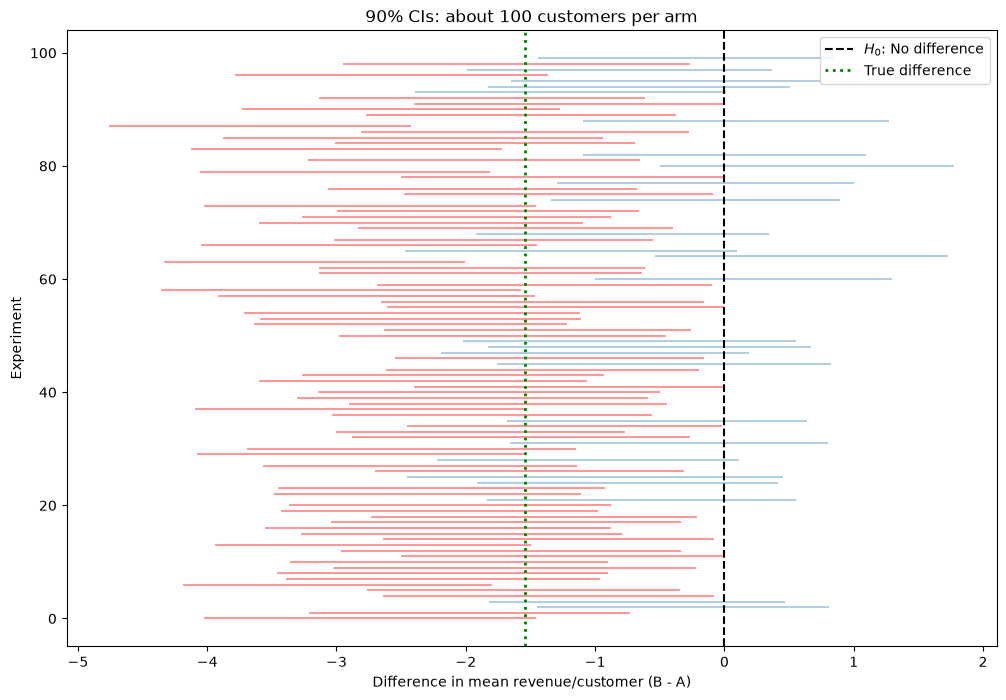

In [5]:
p_A = 10.00
p_B = 15.00
experiment_size = 100
CIs = []
for i in range(100):
    sales_A = sales(p_A, mean_customers = experiment_size, rng=rng) * p_A # Compute revenue for each customer in A
    sales_B = sales(p_B, mean_customers = experiment_size, rng=rng) * p_B # Compute revenue for each customer in B
    revenue_A = sales_A.mean() # Mean revenue per arriving customer in A
    revenue_B = sales_B.mean() # Mean revenue per arriving customer in B
    delta_R = revenue_B - revenue_A # Difference in mean revenue per arriving customer
    std_error = np.sqrt(
        np.var(sales_A, ddof=1) / len(sales_A) +
        np.var(sales_B, ddof=1) / len(sales_B)
    ) # Standard Error
    confidence_interval = (delta_R - 1.645 * std_error, delta_R + 1.645 * std_error)
    CIs.append(confidence_interval)

CIs = np.array(CIs)

fig, ax = plt.subplots(figsize=(12, 8))

for i, (lower, upper) in enumerate(CIs):
    ax.hlines(
        y=i,
        xmin=lower,
        xmax=upper,
        color='steelblue' if lower <= 0 <= upper else 'red',
        alpha=0.4,
        linewidth=1.5
    )

ax.axvline(0, color='black', linestyle='--', label='$H_0$: No difference')

# Model-based truth for checking coverage, not an estimate from these experiments.
true_delta = p_B * purchase_probability(p_B) - p_A * purchase_probability(p_A)
ax.axvline(
    true_delta,
    color='green',
    linestyle=':',
    linewidth=2,
    label='True difference'
)

ax.set_xlabel('Difference in mean revenue/customer (B - A)')
ax.set_ylabel('Experiment')
ax.set_title(f'90% CIs: about {experiment_size} customers per arm')
ax.legend()

plt.show()

## Statistical Power
- Our CIs cover the true param about 90% of the time, as they should, but whether or not we reject the null of 0 depends on the size of the experiment (the number of customers we experiment on)
- We define **(empirical) power** as
$$
\widehat{\text{Power}} = \dfrac{\text{Number of CIs excluding zero}}{\text{Number of Experiments}}
$$
and **(empirical) coverage** as
$$
\widehat{\text{Coverage}} = \dfrac{\text{Number of CIs including the true parameter value}}{\text{Number of Experiments}}
$$
- So you can see that as we increase the mean customers per experiment, the power increases significantly
- A nonsignificant result from an underpowered experiment does not establish that there is no effect
- Larger experiments require more customers and time, potentially spent at suboptimal prices
- Especially if the changes in price are small, the experiment will need to be powered to detect changes in revenue
- Potential gains from adjusting the price must be weighed against the cost of the experiment

<div style="border: 2px solid blue; padding: 8px 12px;">

* power = what fraction of intervals exclude zero? 
    * check lower bound above 0 or upper bound below 0
* coverage = what fraction contain the true difference?
    * check is true value falls inside the interval

In [6]:
power = np.mean(
    (CIs[:, 0] > 0) | (CIs[:, 1] < 0)
)
print(f"Empirical power: {power:.3%}")

coverage = np.mean(
    (CIs[:, 0] <= true_delta) & (CIs[:, 1] >= true_delta)
)
print(f"Empirical coverage/confidence (around 90%): {coverage:.3%}")


Empirical power: 74.000%
Empirical coverage/confidence (around 90%): 84.000%


<div style="border: 2px solid blue; padding: 8px 12px;">

**Confidence (coverage) is fixed by the multiplier you choose (1.645 for 90%). Sample size doesn't change it.**

**Power depends on sample size. It's your chance of detecting a real effect.**

## Power versus Confidence
- So the power varies with the size of the experiment: We're comparing to a null of zero
- Empirical coverage stays around 90%, with simulation noise and Normal-approximation error: We're cheating, and asking if the true value of the parameter is included in the interval
- This should help resolve a bit of the confusion around what confidence intervals are and how hypothesis testing works

***
## 2. Searching for the Optimal Price
- We have two broad strategies for searching for the optimal price:
    1. Grid Search: Pick a grid between 0 and 150, evaluate each price, and compare estimated revenue.
    2. Local Search: Use gradient ascent. Compare two nearby prices, $p_t-h$ and $p_t+h$, using fresh, independent customer samples:
    $$
    \hat g_t = \frac{\hat r(p_t+h)-\hat r(p_t-h)}{2h},
    \qquad p_{t+1}=p_t+\ell_t\hat g_t.
    $$
- Here $\hat r(p)$ is observed mean revenue per arriving customer, $h$ is the step size, and $\ell_t$ is the learning rate.

- Because expected traffic is independent of price, maximizing expected revenue per customer also maximizes expected total revenue for the same market size.
    - *Customer count is the same regardless of price, so you can work with per-customer revenue.*
- The code clips prices to $[0,75]$, adjusts the slope denominator at the boundaries, and limits each move to 2 price units.
    - *Safety rails: prices can't leave the allowed range, and one noisy estimate can't send you far away.*
- A 90% interval containing zero can reflect low power; it does not certify an optimum. We use a fixed iteration budget and reduce the learning rate over time.
    - *If the slope's CI includes 0, you may be at the peak, or you may just not have enough data to see the slope.*
    - *You stop after a set number of steps, and steps shrink so the price settles instead of bouncing around from noise.*
- These are pointwise intervals for individual comparisons. Repeated adaptive testing does not provide an overall 90% guarantee for the selected price.
    - *Each CI is valid by itself, but checking many times and choosing based on the results makes the combined error rate larger than 10%.*


## Local Search
- You do not **have** to use local search based on the gradient: You could do something with sequential grid search
- Local search is potentially a powerful tool to refine your price in a neighborhood of the optimum, using inference and optimization together

In [7]:
def estimate_gradient(price, *, step=1.0, mean_customers=300, rng=None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low = max(0, price - step)
    price_high = min(75, price + step)
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - 1.645 * se) / gap,
        "ci_high": (difference + 1.645 * se) / gap,
        "customers": len(low) + len(high),
    }


# A positive slope suggests raising the price; a negative slope suggests lowering it.
local_experiment = estimate_gradient(price=30, rng=2026)
pd.DataFrame([local_experiment]).round(3)


,price,gradient,gradient_se,ci_low,ci_high,customers
0,30.0,-0.791,0.581,-1.747,0.165,607


In [8]:
def gradient_ascent(start_price, *, iterations=80, step=1.0,
                    learning_rate=2.0, mean_customers=300, seed=100):
    """Use a fixed experiment budget and a decreasing learning rate."""
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 75))
    records = []
    for iteration in range(iterations):
        estimate = estimate_gradient(price, step=step,
                                     mean_customers=mean_customers, rng=search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1, **estimate,
                        "learning_rate": rate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)


path = gradient_ascent(start_price=32, seed=2058)
path[["iteration", "price", "gradient", "ci_low", "ci_high", "next_price"]].head(10)


,iteration,price,gradient,ci_low,ci_high,next_price
0,1,32.000000,-1.903697,-2.820153,-0.987240,30.000000
1,2,30.000000,-2.101038,-3.045292,-1.156785,28.000000
2,3,28.000000,-0.816932,-1.748906,0.115042,27.056688
3,4,27.056688,0.219296,-0.664990,1.103582,27.275984
4,5,27.275984,0.055137,-0.842240,0.952513,27.325300
5,6,27.325300,0.526859,-0.384295,1.438013,27.755479
6,7,27.755479,0.190000,-0.723219,1.103219,27.899105
7,8,27.899105,0.293042,-0.660448,1.246532,28.106317
8,9,28.106317,0.146214,-0.800387,1.092814,28.203793
9,10,28.203793,-0.077915,-0.967813,0.811983,28.154515


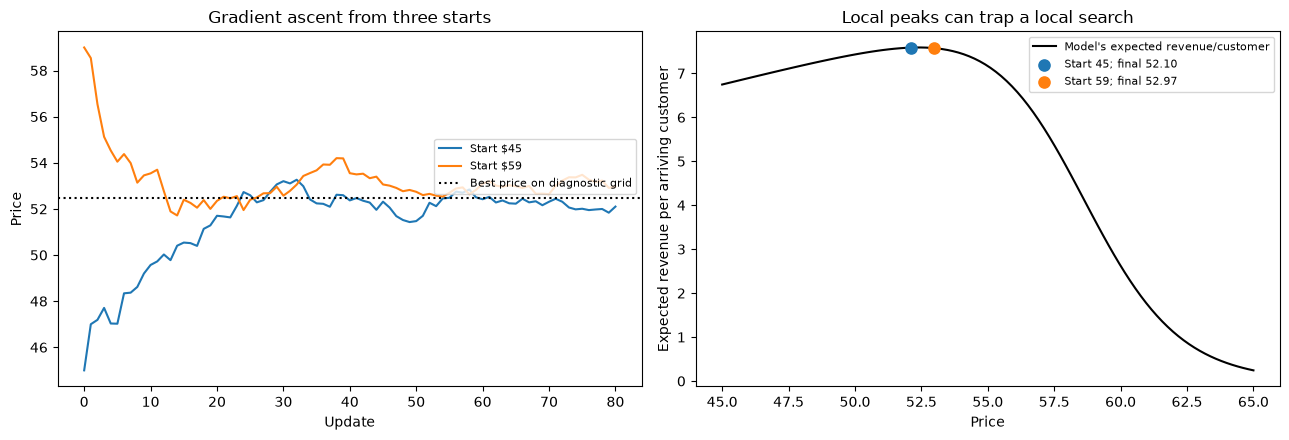

,start_price,final_price,search_customers,validation_customers,validation_revenue_per_customer,validation_se
0,45.0,52.100,47895,10036,7.548,0.183
1,59.0,52.973,47770,9894,7.678,0.187


In [9]:
# Only the diagnostic plot uses the model's true purchase curve.
# The search itself uses sales() at two nearby prices on every iteration.
starts = [45.0, 59.0]
ascent_paths = {
    start: gradient_ascent(start, seed=2026 + int(start))
    for start in starts
}
price_grid = np.linspace(45, 65, 100)
expected_revenue_per_customer = price_grid * purchase_probability(price_grid)
grid_best_price = price_grid[np.argmax(expected_revenue_per_customer)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[1].plot(price_grid, expected_revenue_per_customer,
             color="black", label="Model's expected revenue/customer")
evaluation_rng = np.random.default_rng(9001)
summary = []
for index, (start, history) in enumerate(ascent_paths.items()):
    color = f"C{index}"
    prices = np.r_[start, history["next_price"].to_numpy()]
    final_price = prices[-1]
    axes[0].plot(np.arange(len(prices)), prices,
                 color=color, label=f"Start ${start:g}")
    axes[1].scatter(final_price, final_price * purchase_probability(final_price),
                    color=color, s=65, zorder=3,
                    label=f"Start {start:g}; final {final_price:.2f}")

    # Evaluate the selected price with fresh customers, outside the search data.
    validation = final_price * sales(final_price, mean_customers=10_000,
                                      rng=evaluation_rng)
    summary.append({
        "start_price": start,
        "final_price": final_price,
        "search_customers": int(history["customers"].sum()),
        "validation_customers": len(validation),
        "validation_revenue_per_customer": validation.mean(),
        "validation_se": validation.std(ddof=1) / np.sqrt(len(validation)),
    })

axes[0].axhline(grid_best_price, color="black", linestyle=":",
                label="Best price on diagnostic grid")
axes[0].set(xlabel="Update", ylabel="Price", title="Gradient ascent from three starts")
axes[1].set(xlabel="Price", ylabel="Expected revenue per arriving customer",
            title="Local peaks can trap a local search")
axes[0].legend(loc="center right", bbox_to_anchor=(1, 0.62), fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

pd.DataFrame(summary).round(3)


***
<div style="border: 2px solid red; padding: 8px 12px;">

## Lab
- You submit an .ipynb or .py that does two things:
    1. Determines an optimal price algorithmically (your code searches for and discovers an optimal price)
    2. Tracks the total number of consumers you have experimented with (at the optimum, each consumer has an expected profit of $11.925)

- The optimal price is between 0 and 70: There is no reason to consider prices outside that range
- There are multiple prices that appear optimal, but only one is globally optimal

- Provide a 1-3 page write-up explaining your design, including tables and plots as necessary:
    1. A one-paragraph summary of the problem
    2. Two paragraphs about how your design handles uncertainty about changes in revenue and selects prices
    3. Two paragraphs about challenges you faced and how you resolved them
    4. One paragraph that summarizes your results. In particular, how many consumers did you experiment on, what were your revenues during the experiments, and what percentage of the optimal profit ($11.925 per customer) did you capture?


## Lab Code: Price Search and Customer Tracking

We tried two approaches:
- **Experiment A:** local search with gradient ascent
- **Experiment B:** coarse grid with Z-test pruning, then a finer grid

### Experiment A: Local Search (Gradient Ascent)

Runs `gradient_ascent` from different starting prices, then spot-checks the prices it lands on with a large sample.

In [10]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [11]:
trial_1 = gradient_ascent(start_price = 26.5, seed=2000)
print(trial_1[["iteration", "price", "gradient", "ci_low", "ci_high", "next_price"]])



    iteration      price  gradient    ci_low   ci_high  next_price
0           1  26.500000  0.507348 -0.347422  1.362118   27.514697
1           2  27.514697 -0.150250 -1.084670  0.784171   27.302211
2           3  27.302211  0.246179 -0.633777  1.126135   27.586475
3           4  27.586475  0.155427 -0.765211  1.076064   27.741901
4           5  27.741901  0.613288 -0.317860  1.544436   28.290443
5           6  28.290443  0.258064 -0.688453  1.204580   28.501151
6           7  28.501151 -0.040587 -0.970622  0.889449   28.470470
7           8  28.470470 -1.037327 -1.948639 -0.126016   27.736969
8           9  27.736969 -0.584677 -1.510461  0.341106   27.347185
9          10  27.347185 -1.070077 -1.967949 -0.172205   26.670409
10         11  26.670409  0.160172 -0.742714  1.063057   26.766996
11         12  26.766996 -0.023380 -0.939886  0.893126   26.753497
12         13  26.753497 -0.602966 -1.474198  0.268266   26.419032
13         14  26.419032  0.176414 -0.706198  1.059025   26.51

In [12]:
trial_2 = gradient_ascent(start_price = 28, seed=2000)
print(trial_2[["iteration", "price", "gradient", "ci_low", "ci_high", "next_price"]])

    iteration      price  gradient    ci_low   ci_high  next_price
0           1  28.000000 -0.078851 -0.973879  0.816177   27.842298
1           2  27.842298 -0.377996 -1.319519  0.563528   27.307731
2           3  27.307731  0.201209 -0.678450  1.080868   27.540067
3           4  27.540067  0.204579 -0.715109  1.124268   27.744647
4           5  27.744647  0.613305 -0.317935  1.544545   28.293203
5           6  28.293203  0.258045 -0.688563  1.204654   28.503896
6           7  28.503896 -0.040632 -0.970757  0.889494   28.473182
7           8  28.473182 -1.037465 -1.948863 -0.126066   27.739583
8           9  27.739583 -0.584769 -1.510640  0.341102   27.349737
9          10  27.349737 -1.070216 -1.968172 -0.172260   26.672873
10         11  26.672873  0.160146 -0.742823  1.063115   26.769445
11         12  26.769445 -0.023421 -0.940011  0.893169   26.755923
12         13  26.755923 -0.603061 -1.474373  0.268250   26.421405
13         14  26.421405  0.176391 -0.706300  1.059082   26.51

In [ ]:
# Figure 1: price paths for all four starting prices (trial_1, trial_2 and the two starts from the earlier plot)
paths = {
    "Start $26.50": trial_1,
    "Start $28": trial_2,
    "Start $45": ascent_paths[45.0],
    "Start $59": ascent_paths[59.0],
}

fig, ax = plt.subplots(figsize=(8, 5))
for i, (label, history) in enumerate(paths.items()):
    prices = history["next_price"].to_numpy()
    line, = ax.plot(np.arange(1, len(prices) + 1), prices, label=label)
    # highlight and label where each path ends up (its local peak)
    ax.scatter(len(prices), prices[-1], color=line.get_color(), s=70, zorder=3,
               edgecolor="black")
    ax.annotate(f"${prices[-1]:.2f}", (len(prices), prices[-1]),
                textcoords="offset points", xytext=(8, 6 - 12 * (i % 2)),
                fontsize=9, fontweight="bold")
ax.set(xlabel="Update", ylabel="Price [$]", title="Gradient ascent price paths")
ax.margins(x=0.1)
ax.legend()
fig.tight_layout()
plt.show()


**Figure 1.** Gradient ascent price paths. Runs started near $27 wander between about $26 and $29 and end near $27, while runs started at $45 and $59 settle on a different local peak near $52-$53.

In [14]:
# diagnostic only (not part of the search, so not counted toward total customers):
# check expected revenue per customer at the prices gradient ascent found
# note: at 10,000 customers the standard error is ~$0.15, larger than the ~$0.05 gap to the optimum,
# so this only confirms the prices are near-optimal; use 100,000 (SE ~$0.05) to resolve smaller differences
size = 10000
guess1 = sales(price=27.09, mean_customers=size, rng=rng) * 27.09
gues1_1 = guess1.mean().sum()
gues1_1

np.float64(11.904554575858922)

In [15]:
guess2 = sales(price=28.21, mean_customers=size, rng=rng) * 28.21
guess2_2 = guess2.mean().sum()
guess2_2

np.float64(11.708869445536768)

### Experiment B: Coarse Grid + Z-Test Pruning

Strategy: **coarse grid, prune losers with the Z-test, then refine locally.**
1. Test a coarse grid of prices ($5 to $70) with small samples.
2. Drop any price that is significantly worse than the current best (two-sample Z-test).
3. Zoom in around the survivors at $1 spacing with bigger samples and prune again.
4. Every customer and every dollar of revenue from the experiments is tracked and cached by price.

#### AI Statement:
Claude was used in the below function 'price_simulator' to help with coding the metric calculations such as variance, and SE, and the diff operations

In [16]:
def price_simulator(p_tests, size=100, z_cutoff=1.645, seed=5030, max_iterations=10):

    rng = np.random.default_rng(seed)

    rows = []

    iter = 0

    while iter < max_iterations: #number of iterations will be no greater than max_iterations

        for i in p_tests:
            customers = sales(i, mean_customers=size, rng=rng) * i #computing the revenue for each customer at price i

            rows.append({'Price': i, 'Customers': len(customers),
                        'Revenue': customers.sum(), 'Revenue_Sq': (customers ** 2).sum()}) #adding the price, number of customers, total revenue, and total revenue squared to the rows list

        each_price_df = pd.DataFrame(rows) #creating a dataframe from the rows list

        results = each_price_df.groupby('Price')[['Customers', 'Revenue', 'Revenue_Sq']].sum() #grouping the data by price and summing the number of customers, total revenue, and total revenue squared for each price

        results['Mean'] = results['Revenue'] / results['Customers'] #average revenue per customer for each price
        variance = (results['Revenue_Sq'] - results['Customers'] * results['Mean'] ** 2) / (results['Customers'] - 1) #computing the variance of revenue per customer for each price
        results['SE'] = np.sqrt(variance / results['Customers']) #computing the standard error of the mean revenue per customer for each price

        best_price = results['Mean'].idxmax() #picking the price with the highest mean revenue per customer
        diff = results.loc[best_price, 'Mean'] - results['Mean'] #subtracting the mean revenue per customer for each price from the best price's mean revenue per customer
        diff_se = np.sqrt(results.loc[best_price, 'SE'] ** 2 + results['SE'] ** 2) #computing the standard error of the gap
        results['Z'] = diff / diff_se #getting the z-score for each price's mean revenue per customer compared to the best price's mean revenue per customer

        keeps = []
        for i in results.index:
            if i == best_price or results.loc[i, 'Z'] < z_cutoff: #checking if the z-score is less than the cutoff and if the price is not the best price (want prices that are not statistically significantly different than best price)
                keeps.append(i) #appending the price to the keeps list if it meets the criteria

        p_tests = keeps #creating the list of prices to test in the next iteration

        iter += 1 #incrementing the iteration counter

        if len(p_tests) == 1: #breaking the loop if there is only one price left to test
            break
        
    # ADDITION:
    # Adding total customers and revenue and percent optimal
    total_customers = each_price_df['Customers'].sum()
    total_revenue = each_price_df['Revenue'].sum()

    average_revenue = total_revenue/total_customers
    percent_optimal=(average_revenue/11.92) * 100

    return(best_price, each_price_df, total_customers, total_revenue, percent_optimal)

[5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 55.0, 60.0, 65.0, 70.0]
Final result: $30.0
Total Customers: 4638
Total Revenue: 42330.0
Percent of Optimal Revenue: 76.57%


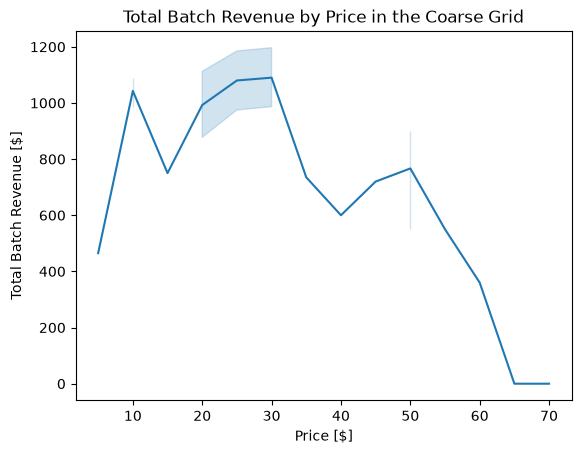

In [17]:
p_tests = [float(p) for p in range(5, 71, 5)]   # setting the prices to test from $5 to $70 in increments of $5
print(p_tests)

best_price, each_price_df, total_customers, total_revenue, percent_optimal = price_simulator(p_tests, size=100, z_cutoff=1.645) #assigning what's returned from the price_simulator function to best_price and each_price_df


print(f"Final result: ${best_price}")
print(f'Total Customers: {total_customers}')
print(f'Total Revenue: {total_revenue}')
print(f'Percent of Optimal Revenue: {percent_optimal:.2f}%')

sns.lineplot(data=each_price_df, x='Price', y='Revenue') #plotting the revenue for each price in the final iteration of the price_simulator function
plt.title('Total Batch Revenue by Price in the Coarse Grid')
plt.xlabel('Price [$]')
plt.ylabel('Total Batch Revenue [$]')
plt.show()

The graph above plots the revenue of each batch. The graph below is plotting the average revenue, which would account for different sample sizes. Just another visual for the report that gives some insight

In [ ]:
def mark_peaks(ax, prices, values):
    """Highlight local peaks in gray; the global peak is red and labeled in bold."""
    prices, values = np.asarray(prices), np.asarray(values)
    best = values.argmax()
    for i in range(len(values)):
        left = values[i - 1] if i > 0 else -np.inf
        right = values[i + 1] if i < len(values) - 1 else -np.inf
        if values[i] >= left and values[i] >= right:
            is_best = i == best
            ax.scatter(prices[i], values[i], s=90 if is_best else 50, zorder=3,
                       color='red' if is_best else 'gray')
            ax.annotate(f'${prices[i]:.0f}: ${values[i]:.2f}', (prices[i], values[i]),
                        textcoords='offset points', xytext=(0, 10), ha='center',
                        fontsize=9, fontweight='bold' if is_best else 'normal')

price_customer_revenue = each_price_df.groupby('Price')[['Customers', 'Revenue']].sum()
price_customer_revenue['Mean Revenue'] = price_customer_revenue['Revenue']/price_customer_revenue['Customers']
print(f'mean revenue from bathces: {price_customer_revenue['Mean Revenue'].tolist()}')

fig, ax = plt.subplots()
sns.lineplot(data=price_customer_revenue.reset_index(), x='Price',
             y='Mean Revenue', ax=ax)
mark_peaks(ax, price_customer_revenue.index, price_customer_revenue['Mean Revenue'])
ax.set_title('Estimated Revenue per Customer by Price ($5–$70 coarse grid)')
ax.set_xlabel('Price [$]')
ax.set_ylabel('Mean Revenue per Customer [$]')
ax.margins(y=0.12)
plt.show()

**Figure 2.** Estimated mean revenue per customer at each price in the coarse grid ($5–$70, $5 steps). Revenue per customer peaks in the high-$20s to low-$30s, which is where the finer grid is centered.

[25.0, 26.0, 27.0, 28.0, 29.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0]
Final result: $28.0
Total Customers: 1092
Total Revenue: 10979.0
Percent of Optimal Revenue: 84.35%


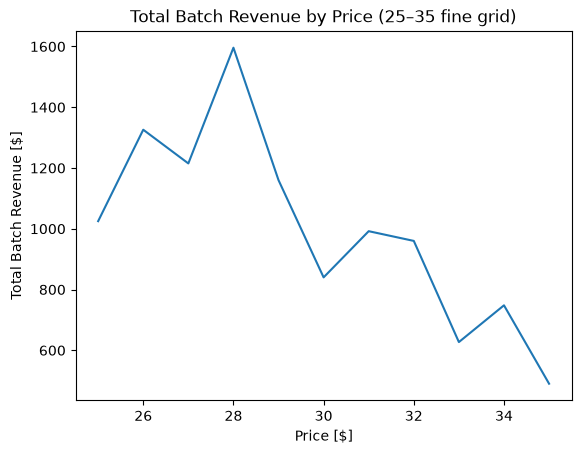

In [19]:
low = best_price - 5
high = best_price + 6
p_tests = [float(p) for p in np.arange(low, high, 1)]
print(p_tests)

best_price, each_price_df, total_customers, total_revenue, percent_optimal = price_simulator(p_tests, size=100, z_cutoff=1.645)

print(f"Final result: ${best_price}")
print(f'Total Customers: {total_customers}')
print(f'Total Revenue: {total_revenue}')
print(f'Percent of Optimal Revenue: {percent_optimal:.2f}%')

sns.lineplot(data=each_price_df, x='Price', y='Revenue')
plt.title(f'Total Batch Revenue by Price (${low:.0f}–${high - 1:.0f} fine grid)')
plt.xlabel('Price [$]')
plt.ylabel('Total Batch Revenue [$]')
plt.show()

In [ ]:
price_customer_revenue = each_price_df.groupby('Price')[['Customers', 'Revenue']].sum()
price_customer_revenue['Mean Revenue'] = price_customer_revenue['Revenue']/price_customer_revenue['Customers']
print(f'mean revenue from bathces: {price_customer_revenue['Mean Revenue'].tolist()}')

fig, ax = plt.subplots()
sns.lineplot(data=price_customer_revenue.reset_index(), x='Price',
             y='Mean Revenue', ax=ax)
mark_peaks(ax, price_customer_revenue.index, price_customer_revenue['Mean Revenue'])
ax.set_title(f'Estimated Revenue per Customer by Price (${low:.0f}–${high - 1:.0f} grid)')
ax.set_xlabel('Price [$]')
ax.set_ylabel('Mean Revenue per Customer [$]')
ax.margins(y=0.12)
plt.show()

**Figure 3.** Estimated mean revenue per customer at each price in the finer $1-step grid around the coarse-grid winner. Prices that were pruned early have fewer observations and noisier estimates.

Testing the stability of price_simulator at different seeds 
---

In [21]:
results = [] # list for saving the results

for seed in range(30): # try 30 different samples
    # use Maddie's algorithm to find the price, num_customers and revenue of each sample
    price, df, customers, revenue, percent_optimal = price_simulator(
        p_tests, size=100, seed=seed) 
    # append results
    results.append({
        'seed': seed, 'best price': price, 
        'customers': customers,
        'revenue': revenue,
        'percent of optimal': percent_optimal
    })

results_df = pd.DataFrame(results) # create df
display(results_df)
display(results_df.describe())
display(results_df['best price'].value_counts())

,seed,best price,customers,revenue,percent of optimal
0,0,28.0,5158,56744.0,92.291638
1,1,28.0,5447,58845.0,90.630826
2,2,28.0,4546,50797.0,93.741603
3,3,28.0,5345,59407.0,93.242446
4,4,28.0,5827,63408.0,91.289911
5,5,28.0,4949,53083.0,89.983266
6,6,27.0,5405,60447.0,93.821592
7,7,27.0,4309,47585.0,92.644006
8,8,27.0,3240,34587.0,89.555369
9,9,28.0,4317,47060.0,91.452087


,seed,best price,customers,revenue,percent of optimal
count,30.000000,30.000000,30.000000,30.000000,30.000000
mean,14.500000,27.333333,4555.233333,50113.966667,92.012690
std,8.803408,0.958927,975.294675,11212.203704,2.629647
min,0.000000,25.000000,1995.000000,20338.000000,85.280241
25%,7.250000,27.000000,4219.750000,47128.750000,90.855203
50%,14.500000,27.500000,4737.500000,51814.000000,92.140427
75%,21.750000,28.000000,5239.000000,58319.750000,93.637732
max,29.000000,29.000000,6421.000000,70407.000000,97.897438


best price
28.0    13
27.0     9
26.0     5
29.0     2
25.0     1
Name: count, dtype: int64

In [ ]:
# Figure 4: how often each price is selected across the 30 seeds
counts = results_df['best price'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(counts.index.astype(int).astype(str), counts.values, color='steelblue')
top = counts.values.argmax()
bars[top].set_color('red')  # highlight the most frequently selected price
ax.annotate(f"Peak: ${counts.index[top]:.0f} ({counts.values[top]} seeds)",
            (top, counts.values[top]), textcoords="offset points", xytext=(0, 6),
            ha="center", fontweight="bold")
ax.set(xlabel="Selected price [$]", ylabel="Number of seeds",
       title="Price selected across 30 seeds")
ax.margins(y=0.12)
fig.tight_layout()
plt.show()


**Figure 4.** Price selected by the finer-grid stage across 30 random seeds. Most runs choose $27 or $28 (22 of 30).

## Issues to Consider

- How much data do you want to gather?
- Do you really want 90/95/99% confidence for setting prices?
- How do you combine brute force grid search?
- What is the minimum step size between prices you want to test?
- How should you adjust your sample size based on the information you are getting at a given price?
- If you cache experiments, can you gather data incrementally to constrain costs?